# Predicting Future Customer Churn with Real-World Telecom Data

### A reproducible, duplicate-aware supervised classification study

**Author:** Jorge Hernández Torres  
**Toolkit:** Python · pandas · NumPy · scikit-learn · Matplotlib  
**Source:** [UCI Iranian Churn dataset](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset) · [DOI 10.24432/C5JW3Z](https://doi.org/10.24432/C5JW3Z) · CC BY 4.0

> **Data:** The original open-licensed UCI dataset, **not** synthetic data. It contains 3,150 customer observations and 13 reported inputs, with customer behavior summarized over the first nine months and a churn outcome at month 12. The provider's dataset metadata establishes a three-month prediction gap. This is a self-directed portfolio analysis based on the public UCI dataset. The code, questions and figures were prepared for this study, with AI assistance for implementation and documentation review.

**Data-quality update (November 2026):** An initial executed analysis identified repeated input profiles. We therefore revised the evaluation to keep identical predictor profiles within the same split and fold. This post-audit protocol is a methodological robustness improvement, **not** a prospective or preregistered design. Scores from the earlier record-wise random split must not be mistaken for results of the revised protocol.

**Important limits:** Observational tabular data do not establish causality. A ranking model does **not** show that contacting a predicted churner prevents churn. We have no per-customer action history, experimental intervention, production timestamps or external holdout population. The analysis is a methodological case study, not a deployed system.

## 1. Objectives and study design

This is a **binary classification** problem: use features measured within the first nine months to estimate the chance of customer churn by month 12. The analysis addresses four research questions:

1. **Predictive signal:** Can observed operational patterns rank future churners better than a prevalence-only baseline?
2. **Generalization:** How do logistic regression and nonlinear ensemble models compare under stratified cross-validation and on an untouched holdout?
3. **Limited review capacity:** What proportion of observed churners fall among the 15% highest-scoring customers? This evaluates *concentration*, not the effectiveness of a retention intervention.
4. **Failure modes:** How sensitive are the conclusions to calibration, threshold choice, feature dependence and a potentially near-target status indicator?

**Evaluation protocol (revised after data-quality audit):** Reserve approximately 20% of data as a profile-disjoint holdout, with approximate class balance; select the candidate with the highest mean five-fold group-disjoint development average precision; estimate a high-recall F2 threshold on group-disjoint development out-of-fold scores; refit the selected model on all development data; evaluate on the group-disjoint holdout **once in this revised protocol**. The protocol was revised after reviewing results from a prior row-wise split, so this is not an independently pre-registered test. A separate 15% review capacity is used as a fixed, illustrative ranking scenario. The primary feature set deliberately excludes `Status` (potential target proxy), `Customer Value` (derivation/timing unclear), and `Age`/`Age Group` (demographic attributes).

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    classification_report, confusion_matrix, precision_recall_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, cross_val_predict, cross_val_score,
)

# Allows execution from either repository root or notebooks/.
ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / 'src' / 'data.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open Jupyter Lab from the repository root or notebooks/ directory.')
sys.path.insert(0, str(ROOT))

from src.data import (load_uci_csv, data_audit, TARGET, MODEL_FEATURES,
                      EXCLUDED_FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES)
from src.evaluation import (capacity_metrics, operating_point, probability_metrics,
                            select_f2_threshold, profile_bootstrap_intervals)
from src.modeling import (SEED, compare_candidates, make_candidates,
                          profile_disjoint_holdout)

DATA_PATH = ROOT / 'data' / 'iranian_churn.csv'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
TOP_FRACTION = 0.15
pd.set_option('display.max_columns', 20)
print('Project directory:', ROOT.name)
print('Random seed:', SEED)

Project directory: telecom-churn-risk-modeling
Random seed: 42


## 2. Data provenance and quality audit

The CSV is retrieved **directly from the original UCI repository**. License: [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/). UCI citation: *Iranian Churn [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5JW3Z.*

The source is an observational sample of one Iranian telecom provider; its sampling procedure, representativeness and exact collection timestamps are not fully documented. The schema validator rejects a partially downloaded CSV, unexpected fields or an incompatible target. The downloaded CSV is deliberately excluded from version control and can be obtained again using `python scripts/download_data.py`.

In [2]:
if not DATA_PATH.exists():
    print('Original UCI CSV not present. Attempting the documented UCI download...')
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'download_data.py')],
                   cwd=ROOT, check=True)

df = load_uci_csv(DATA_PATH)
audit = data_audit(df)
print('Dataset audit:')
for key, value in audit.items():
    print(f'  {key}: {value}')
print('Target distribution (counts):')
display(df[TARGET].value_counts().rename(index={0:'Non-churn', 1:'Churn'}).to_frame('customers'))
print('Column types:')
display(df.dtypes.rename('dtype').to_frame().T)
# Only a limited display: no customer identifiers are present in the UCI CSV.
display(df.head(3))
assert len(df) == 3150 and df[TARGET].isin([0, 1]).all()

Dataset audit:
  rows: 3150
  columns: 14
  positive_count: 495
  prevalence: 0.15714285714285714
  missing_values: 0
  identical_full_rows: 300
  duplicate_feature_vectors: 365
  conflicting_target_profiles: 18
Target distribution (counts):


,customers
Churn,
Non-churn,2655
Churn,495


Column types:


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0


## 3. Profile-disjoint holdout split before exploratory analysis

The dataset audit identifies repeated records and input profiles. **Identical input vectors are not proven to represent the same customer**, as UCI does not provide a persistent individual ID. Nonetheless, allowing identical profiles in training and holdout can lead to an overly optimistic estimate, especially with flexible models. We therefore impose a stronger evaluation constraint: **all exact nine-feature predictor profiles must stay together in either development or holdout**. We apply the same grouping to every development cross-validation fold.

A deterministic group-shuffle search selects a partition **close to** 80/20 with **approximate** target prevalence balance. The size and class ratios need not be exactly 80/20 or identical. Grouping is formed solely from predictors and does not group observations based on the label; opposing labels for identical predictors are explicitly counted. No performance metric is considered while constructing splits.

This protocol is a **post-audit revision** prompted by a previously executed row-wise analysis. It is stronger against repeat-profile overlap, but does not create a genuinely new external test or establish unique-customer independence. All findings remain exploratory on one historical dataset.

In [3]:
dev_idx, test_idx, all_profile_groups = profile_disjoint_holdout(
    df, features=MODEL_FEATURES, target=TARGET, fraction=0.20, seed=SEED,
)
development = df.iloc[dev_idx].copy().reset_index(drop=True)
holdout = df.iloc[test_idx].copy().reset_index(drop=True)
groups_dev = all_profile_groups[dev_idx]
groups_test = all_profile_groups[test_idx]
X_dev = development[list(MODEL_FEATURES)]
y_dev = development[TARGET].astype(int)
X_test = holdout[list(MODEL_FEATURES)]
y_test = holdout[TARGET].astype(int)

print(f'Development: {len(development):,} records ({y_dev.mean():.1%} churn)')
print(f'Holdout:     {len(holdout):,} records ({y_test.mean():.1%} churn)')
print('Repeated original predictor profiles:', audit['duplicate_feature_vectors'])
print('Predictor profiles with conflicting target labels:', audit['conflicting_target_profiles'])
print('Cross-split overlapping predictor profiles:', len(set(groups_dev) & set(groups_test)))
assert len(set(dev_idx) & set(test_idx)) == 0
assert set(groups_dev).isdisjoint(set(groups_test))
assert len(development) + len(holdout) == len(df)
assert y_dev.nunique() == 2 and y_test.nunique() == 2


Development: 2,516 records (15.7% churn)
Holdout:     634 records (15.6% churn)
Repeated original predictor profiles: 365
Predictor profiles with conflicting target labels: 18
Cross-split overlapping predictor profiles: 0


## 4. Exploratory analysis — development data only

The next displays are **associations**, not evidence that complaints or usage *cause* churn. The UCI documentation describes `Complains` as a binary indicator and `Tariff Plan` as a two-category code; numeric usage is not the same as contractual churn risk. We do not use holdout outcomes in any chart at this stage.

Churn rate by complaint indicator (development only):


,churn_rate,n_customers
Complains,,
No complaint,0.1015,2325
Complaint,0.8377,191


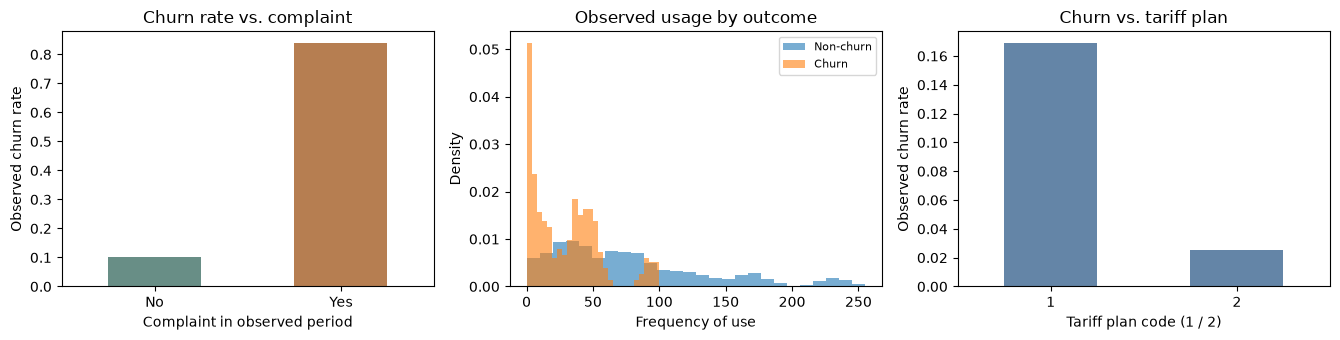

In [4]:
eda = development.copy()
summary = pd.DataFrame({
    'churn_rate': eda.groupby('Complains')[TARGET].mean(),
    'n_customers': eda.groupby('Complains')[TARGET].size(),
}).rename(index={0: 'No complaint', 1: 'Complaint'})
print('Churn rate by complaint indicator (development only):')
display(summary.round(4))

def plot_exploration(data):
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.5))
    data.groupby('Complains')[TARGET].mean().rename(index={0:'No',1:'Yes'}).plot(
        kind='bar', ax=axes[0], color=['#688e86','#b67e51'])
    axes[0].set(title='Churn rate vs. complaint', xlabel='Complaint in observed period', ylabel='Observed churn rate')
    axes[0].tick_params(axis='x', rotation=0)
    axes[1].hist(data.loc[data[TARGET]==0, 'Frequency of use'], bins=26,
                 alpha=.6, density=True, label='Non-churn')
    axes[1].hist(data.loc[data[TARGET]==1, 'Frequency of use'], bins=26,
                 alpha=.6, density=True, label='Churn')
    axes[1].set(xlabel='Frequency of use', ylabel='Density', title='Observed usage by outcome')
    axes[1].legend(fontsize=8)
    data.groupby('Tariff Plan')[TARGET].mean().plot(kind='bar', ax=axes[2], color='#6485a7')
    axes[2].set(xlabel='Tariff plan code (1 / 2)', ylabel='Observed churn rate', title='Churn vs. tariff plan')
    axes[2].tick_params(axis='x', rotation=0)
    fig.tight_layout()
    fig.savefig(FIGURES / 'development_eda.png', dpi=150, bbox_inches='tight')
    plt.show()
plot_exploration(eda)

## 5. Feature eligibility and leakage control

**Primary features (nine):** counts/aggregates for call failures, subscription duration, charge level, call duration, call frequency, SMS frequency and distinct called numbers, plus complaint and tariff-plan indicators. These are documented as first-nine-month summaries.

**Excluded on purpose:**
- `Status`: coded as active/non-active; conceptually close to churn and susceptible to label/proxy leakage. Without a timestamp-level data dictionary we cannot verify deployment-time availability.
- `Customer Value`: calculated by the provider using an unspecified formula; unclear whether it incorporates information unavailable at month nine. It is neither an input nor a proven financial benefit in this notebook.
- `Age` and `Age Group`: demographic attributes; excluded from prediction. Later grouped error rates may be used only as descriptive diagnostics.

Preprocessing is fitted **inside each cross-validation training fold**: numerical median imputation + scaling, categorical most-frequent imputation + one-hot encoding. The original dataset documents no missing values; imputation is a defensive production-style precaution, not a claim that the UCI CSV contains missing entries.

In [5]:
print('Primary predictors:', list(MODEL_FEATURES))
print('Excluded fields:  ', list(EXCLUDED_FEATURES))
assert not set(MODEL_FEATURES).intersection(set(EXCLUDED_FEATURES) | {TARGET})
assert list(X_dev.columns) == list(X_test.columns)

Primary predictors: ['Call Failure', 'Subscription Length', 'Charge Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Complains', 'Tariff Plan']
Excluded fields:   ['Status', 'Customer Value', 'Age', 'Age Group']


## 6. Model comparison on development folds

We compare a constant-probability DummyClassifier with a regularized linear classifier and two nonlinear ensembles. The **primary selection metric is average precision (AP)**, which better emphasizes the ranking of relatively uncommon churn events than accuracy alone. ROC-AUC is shown as a complementary ranking measure. All candidate hyperparameters are fixed before looking at test labels; this is a comparison, not a comprehensive search.

Because models are chosen using these folds, profile-disjoint cross-validation scores may still be slightly optimistic for the final chosen model. The profile-disjoint holdout provides a further check within this revised exploratory protocol; it is not external validation.

In [6]:
cv_results = compare_candidates(X_dev, y_dev, groups=groups_dev, n_splits=5, seed=SEED)
display(cv_results.style.format({'mean_cv_ap':'{:.4f}', 'std_cv_ap':'{:.4f}', 'mean_cv_auc':'{:.4f}'}))

baseline_ap_cv = float(cv_results.loc[
    cv_results['model']=='Prevalence baseline', 'mean_cv_ap'
].iloc[0])
learned_models = cv_results.loc[cv_results['model'] != 'Prevalence baseline']
selected_name = str(learned_models.iloc[0]['model'])
selected_ap_cv = float(learned_models.iloc[0]['mean_cv_ap'])
print(f'Best learned model by development mean AP: {selected_name}')
if selected_ap_cv <= baseline_ap_cv:
    print('CAUTION: No learned model exceeded the prevalence baseline in development CV.')
models = make_candidates(seed=SEED)
selected_estimator = models[selected_name]

,model,mean_cv_ap,std_cv_ap,mean_cv_auc
0,Gradient boosting,0.8880,0.0299,0.9734
1,Random forest,0.8574,0.0422,0.9669
2,Logistic regression,0.7544,0.0552,0.9243
3,Prevalence baseline,0.1574,0.0028,0.5000


Best learned model by development mean AP: Gradient boosting


## 7. Select a decision threshold from training-only out-of-fold scores

Using five-fold **profile-disjoint out-of-fold (OOF)** development predictions, we choose a threshold maximizing F2 (which weights recall more heavily than precision). This is a diagnostic operating point, not an operational outreach policy: an F2-optimal threshold can flag a large fraction of users. Model selection and threshold selection are both completed before accessing the holdout labels.

A separate **top-15% ranked capacity** will be assessed on the final test set independently of the threshold.

In [7]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_scores = cross_val_predict(
    selected_estimator, X_dev, y_dev, cv=cv, groups=groups_dev,
    method='predict_proba', n_jobs=1,
)[:,1]
threshold = select_f2_threshold(y_dev, oof_scores)
oof_point = operating_point(y_dev, oof_scores, threshold)
print('Development OOF F2 operating point (not holdout performance):')
display(pd.DataFrame([oof_point]).round(4))

Development OOF F2 operating point (not holdout performance):


,threshold,precision,recall,f2,flagged_fraction,flagged_count
0,0.1749,0.6803,0.9242,0.8624,0.2138,538


## 8. Final fit and single holdout evaluation

The selected estimator is refit **once** to all development data and then used to score the profile-disjoint holdout (untouched within the revised evaluation). AP, ROC-AUC and Brier score summarize ranking and probability quality; the threshold-based confusion matrix exposes precision/recall tradeoffs. No test labels are used to select a model, threshold or review capacity.

In [8]:
final_model = clone(selected_estimator).fit(X_dev, y_dev)
test_scores = final_model.predict_proba(X_test)[:,1]
test_prob_metrics = probability_metrics(y_test, test_scores)
test_point = operating_point(y_test, test_scores, threshold)
capacity = capacity_metrics(y_test, test_scores, fraction=TOP_FRACTION)
print('Holdout probability metrics:')
display(pd.DataFrame([test_prob_metrics]).round(4))
print('Holdout classification at frozen OOF F2 threshold:')
display(pd.DataFrame([test_point]).round(4))
print('Holdout top-15% concentration (DESCRIPTIVE, not causal uplift):')
display(pd.DataFrame([capacity]).round(4))
print(classification_report(y_test, test_scores >= threshold, digits=3, zero_division=0))

Holdout probability metrics:


,average_precision,roc_auc,brier_score,prevalence
0,0.9033,0.9752,0.0415,0.1562


Holdout classification at frozen OOF F2 threshold:


,threshold,precision,recall,f2,flagged_fraction,flagged_count
0,0.1749,0.6118,0.9394,0.8485,0.2397,152


Holdout top-15% concentration (DESCRIPTIVE, not causal uplift):


,fraction,reviewed_count,churners_in_reviewed,precision_at_k,recall_at_k,lift_at_k,prevalence
0,0.15,96,79,0.8229,0.798,5.27,0.1562


              precision    recall  f1-score   support

           0      0.988     0.890     0.936       535
           1      0.612     0.939     0.741        99

    accuracy                          0.897       634
   macro avg      0.800     0.915     0.839       634
weighted avg      0.929     0.897     0.906       634



## 9. Holdout diagnostics: ranking and classification errors

The precision-recall baseline is the **observed holdout prevalence**. ROC-AUC evaluates ranking across thresholds; AP must be interpreted relative to that prevalence. The confusion matrix uses the threshold frozen in §7. These plots describe this sample and do not establish transportability to a new customer cohort.

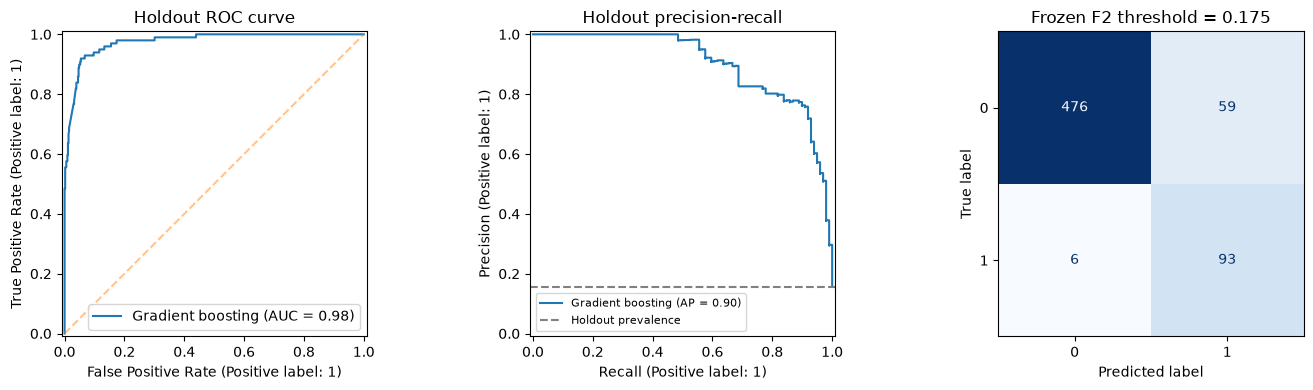

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.0))
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[0], name=selected_name)
axes[0].plot([0,1],[0,1], ls='--', alpha=.45)
axes[0].set_title('Holdout ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[1], name=selected_name)
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='Holdout prevalence')
axes[1].legend(fontsize=8)
axes[1].set_title('Holdout precision-recall')
ConfusionMatrixDisplay.from_predictions(
    y_test, (test_scores >= threshold).astype(int),
    ax=axes[2], cmap='Blues', colorbar=False,
)
axes[2].set_title(f'Frozen F2 threshold = {threshold:.3f}')
fig.tight_layout()
fig.savefig(FIGURES / 'holdout_model_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Does the top-scored 15% concentrate churn events?

In a constrained triage scenario, suppose analysts could *review* 15% of accounts. We rank customers by predicted churn probability and measure the **observed fraction of actual churners among those accounts**, compared with the random-ranking expectation. The result must not be called incremental retention, prevented losses or campaign ROI: the dataset has no experimental treatment/outreach labels.

We also plot cumulative churn capture across increasing review capacity, strictly as an exploratory visualization after the model is frozen.

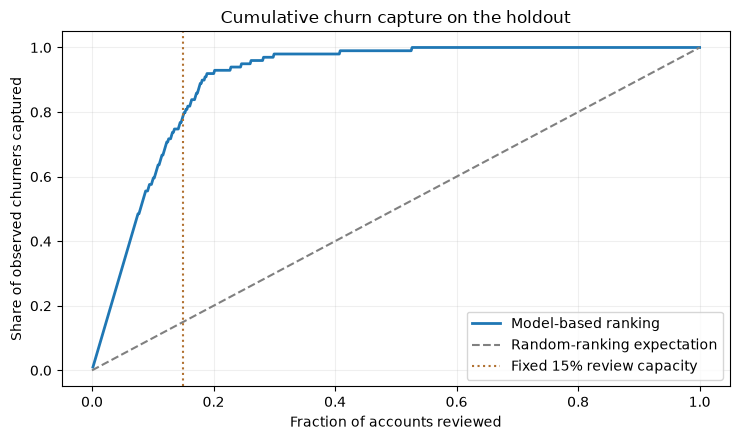

Among top 15% scores: 79 / 99 observed churners; lift 5.27x relative to observed prevalence.


In [10]:
order = np.lexsort((np.arange(len(test_scores)), -test_scores))
sorted_targets = y_test.to_numpy()[order]
reviews = np.arange(1, len(sorted_targets)+1)
cumulative_capture = np.cumsum(sorted_targets) / sorted_targets.sum()
random_capture = reviews / len(sorted_targets)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(random_capture, cumulative_capture, label='Model-based ranking', linewidth=2)
ax.plot([0,1],[0,1],ls='--',color='gray', label='Random-ranking expectation')
ax.axvline(TOP_FRACTION, ls=':', color='#b17131', label='Fixed 15% review capacity')
ax.set(xlabel='Fraction of accounts reviewed', ylabel='Share of observed churners captured',
       title='Cumulative churn capture on the holdout')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIGURES / 'holdout_cumulative_capture.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Among top {TOP_FRACTION:.0%} scores: "
      f"{capacity['churners_in_reviewed']} / {int(y_test.sum())} observed churners; "
      f"lift {capacity['lift_at_k']:.2f}x relative to observed prevalence.")

## 11. Sampling uncertainty and probability calibration

A nonparametric bootstrap of repeated-predictor-profile clusters (300 resamples, fixed holdout model and predictions) gives **conditional percentile ranges, acknowledging identical input-vector clusters** for AP, ROC-AUC and Brier score. These are not full confidence intervals for model development or deployment: they exclude data-collection bias, temporal drift and model-selection uncertainty. A reliability diagram compares empirical churn frequencies across predicted-risk bins; small groups may be unstable.

,metric,holdout,bootstrap_2.5pct,bootstrap_97.5pct
0,average_precision,0.9033,0.8433,0.9487
1,roc_auc,0.9752,0.9600,0.9887
2,brier_score,0.0415,0.0288,0.0556


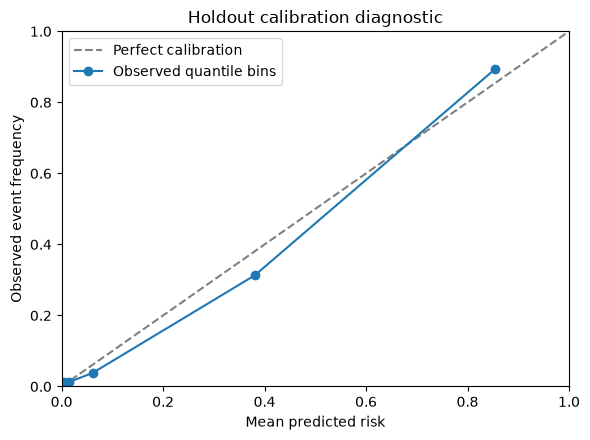

In [11]:
intervals = profile_bootstrap_intervals(y_test, test_scores, groups_test, n_resamples=300, seed=SEED)
interval_table = pd.DataFrame([
    {'metric': name, 'holdout': test_prob_metrics[name],
     'bootstrap_2.5pct': bounds[0], 'bootstrap_97.5pct': bounds[1]}
    for name,bounds in intervals.items()
])
display(interval_table.round(4))

frac_pos, mean_pred = calibration_curve(y_test, test_scores, n_bins=8, strategy='quantile')
fig, ax = plt.subplots(figsize=(6.0, 4.5))
ax.plot([0,1], [0,1], '--', color='gray', label='Perfect calibration')
ax.plot(mean_pred, frac_pos, marker='o', label='Observed quantile bins')
ax.set(xlim=(0,1), ylim=(0,1), xlabel='Mean predicted risk',
       ylabel='Observed event frequency', title='Holdout calibration diagnostic')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'holdout_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Model dependence and robustness checks

Permutation importance measures how much the **fitted classifier's holdout AP** deteriorates after one original input column is independently shuffled. This is a model-dependence measure, **not a causal explanation**. Since the model has already been frozen, we do not use the holdout importance ranking to change its features. Strong correlations between usage measures can distribute importance across several columns.

As a separate *development-only* sensitivity test, logistic regression is evaluated with and without `Status`. If the score rises, that is not evidence that the extra feature is suitable for prospective deployment: its observation timing is insufficiently documented. `Status` stays excluded from the final model.

,feature,mean_ap_drop,std_ap_drop
7,Complains,0.2993,0.0375
4,Frequency of use,0.2657,0.0132
3,Seconds of Use,0.2229,0.0220
0,Call Failure,0.1264,0.0200
1,Subscription Length,0.1095,0.0198
5,Frequency of SMS,0.1006,0.0212
2,Charge Amount,0.0840,0.0101
6,Distinct Called Numbers,0.0313,0.0089
8,Tariff Plan,0.0000,0.0000


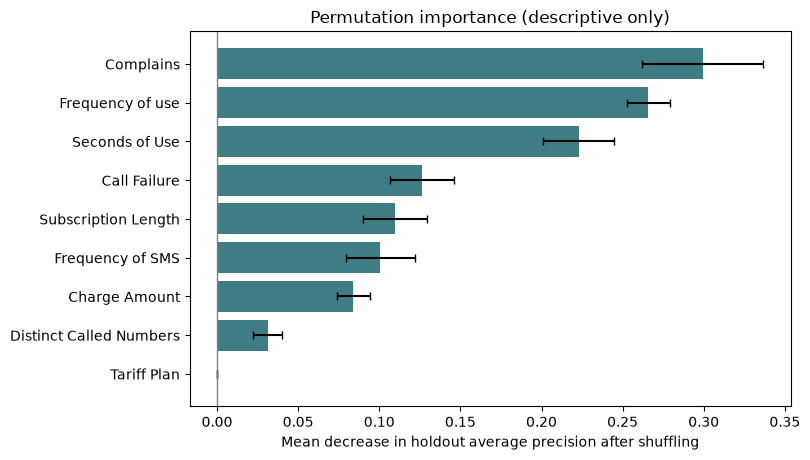

In [12]:
importance = permutation_importance(
    final_model, X_test, y_test, scoring='average_precision',
    n_repeats=8, random_state=SEED, n_jobs=1,
)
feature_importance = pd.DataFrame({
    'feature': list(MODEL_FEATURES),
    'mean_ap_drop': importance.importances_mean,
    'std_ap_drop': importance.importances_std,
}).sort_values('mean_ap_drop', ascending=False)
display(feature_importance.round(4))
fig, ax = plt.subplots(figsize=(8.2, 4.7))
plot_data = feature_importance.sort_values('mean_ap_drop')
ax.barh(plot_data['feature'], plot_data['mean_ap_drop'], xerr=plot_data['std_ap_drop'],
        color='#407c83', capsize=3)
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Mean decrease in holdout average precision after shuffling',
       title='Permutation importance (descriptive only)')
fig.tight_layout()
fig.savefig(FIGURES / 'holdout_permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# All values below are trained/evaluated *only* on development folds.
# This diagnostic does NOT affect the frozen final model.
logistic_no_status = make_candidates(seed=SEED)['Logistic regression']
logistic_with_status = make_candidates(include_status=True,seed=SEED)['Logistic regression']
cv_status = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
without_status = cross_val_score(
    logistic_no_status, development[list(MODEL_FEATURES)], y_dev,
    cv=cv_status, groups=groups_dev, scoring='average_precision', n_jobs=1,
)
with_status = cross_val_score(
    logistic_with_status, development[list(MODEL_FEATURES) + ['Status']], y_dev,
    cv=cv_status, groups=groups_dev, scoring='average_precision', n_jobs=1,
)
status_check = pd.DataFrame({
    'specification':['Primary predictors (no Status)', 'Sensitivity only (+ Status)'],
    'mean_development_cv_ap':[without_status.mean(),with_status.mean()],
    'std_across_folds':[without_status.std(ddof=1), with_status.std(ddof=1)],
})
display(status_check.round(4))
print('Status is excluded from the published final model regardless of this comparison.')

,specification,mean_development_cv_ap,std_across_folds
0,Primary predictors (no Status),0.7544,0.0552
1,Sensitivity only (+ Status),0.7543,0.0527


Status is excluded from the published final model regardless of this comparison.


## 13. Group-level descriptive check (not a fairness certification)

Because the primary predictor set excludes demographics, we can nevertheless *inspect* performance by recorded age group **without fitting on age**. Holdout subgroups with fewer than 30 observations or fewer than 5 churn events are suppressed as too small for useful interpretation. Small sample sizes, incomplete demographics and unmeasured confounders prevent claims of fairness or discrimination.

In [14]:
group_results = []
for group, idx in holdout.groupby('Age Group').groups.items():
    y_g = y_test.iloc[list(idx)].to_numpy()
    p_g = test_scores[np.asarray(list(idx))]
    if len(y_g) < 30 or y_g.sum() < 5 or (y_g == 0).sum() < 5:
        group_results.append({'age_group': int(group), 'n':len(y_g),
                              'observed_churn_rate': float(y_g.mean()),
                              'ap': np.nan, 'note':'Insufficient support'})
    else:
        from sklearn.metrics import average_precision_score
        group_results.append({'age_group': int(group), 'n':len(y_g),
                              'observed_churn_rate': float(y_g.mean()),
                              'ap': float(average_precision_score(y_g,p_g)),
                              'note':'Descriptive only'})
display(pd.DataFrame(group_results).sort_values('age_group').round(4))

,age_group,n,observed_churn_rate,ap,note
0,1,25,0.0000,NaN,Insufficient support
1,2,208,0.1971,0.8780,Descriptive only
2,3,273,0.1465,0.9488,Descriptive only
3,4,89,0.2022,0.9271,Descriptive only
4,5,39,0.0000,NaN,Insufficient support


## 14. Interpretation and limitations

The code cell below generates a **data-dependent conclusion after execution**: no model scores or claim of effective retention are hard-coded into this document. The final interpretation should be read alongside the figures and audit, not divorced from the data.

**What the analysis cannot establish:** true future performance under distribution shift; the benefits or harms of contacting high-risk customers; model-level causality; individual fairness; real monetary returns; or whether `Status`/`Customer Value` were available at the correct deployment timestamp. The dataset is from one provider, and there is no external or out-of-time test set. Repeated predictor profiles motivated profile-disjoint evaluation, but unique-customer independence is still unverifiable; the evaluation was revised after an earlier random-split run and is not preregistered.

**Next steps for production-oriented research:** documented time-stamped events, an out-of-time holdout, monitoring for drift, calibrated business thresholds with verified costs, customer-consent/privacy controls and intervention-effect estimation through a randomized experiment.

In [15]:
ap = test_prob_metrics['average_precision']
baseline_ap = test_prob_metrics['prevalence']
auc = test_prob_metrics['roc_auc']
lift = capacity['lift_at_k']
print('DATA-CONDITIONED CONCLUSION — UCI HOLDOUT')
print(f'Final selected classifier: {selected_name}')
print(f'Observed churn prevalence: {baseline_ap:.1%}; holdout AP: {ap:.3f}; ROC-AUC: {auc:.3f}.')
if ap > baseline_ap:
    print('The selected model shows better AP than the holdout prevalence-only reference.')
else:
    print('The model does not exceed the holdout prevalence reference in AP.')
print(f'At the fixed 15% review capacity: {capacity["recall_at_k"]:.1%} of '
      f'observed churners are in the reviewed subset (lift {lift:.2f}x).')
if lift > 1:
    print('This indicates retrospective concentration, not proven intervention value.')
else:
    print('The capacity ranking provides no positive lift on this holdout.')
print('The performance is internal to this historical dataset. External deployment is NOT validated.')

DATA-CONDITIONED CONCLUSION — UCI HOLDOUT
Final selected classifier: Gradient boosting
Observed churn prevalence: 15.6%; holdout AP: 0.903; ROC-AUC: 0.975.
The selected model shows better AP than the holdout prevalence-only reference.
At the fixed 15% review capacity: 79.8% of observed churners are in the reviewed subset (lift 5.27x).
This indicates retrospective concentration, not proven intervention value.
The performance is internal to this historical dataset. External deployment is NOT validated.


## Reference and reproducibility

- **Original dataset:** *Iranian Churn* (2020), UCI Machine Learning Repository. https://doi.org/10.24432/C5JW3Z.
- **Data license:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), attributed in `DATA_PROVENANCE.md`. Source data are not reproduced by default in the GitHub ZIP.
- **Reproduce:** `python scripts/download_data.py` → `jupyter lab` → open this notebook → **Run All**. The data download requires an internet connection once; subsequent executions are offline. Code dependencies are listed in `requirements.txt`.
- **Project scope:** Self-directed portfolio analysis of the publicly available UCI dataset. Scores shown after executing this revised notebook apply to profile-disjoint evaluation; earlier random-split scores are not carried forward.